# Détection de PII (Persanally Identifiable Information) et anonymisation des textes 
**Dataset :** [`ai4privacy/pii-masking-300k`](https://huggingface.co/datasets/ai4privacy/pii-masking-300k) 

## Objectif
Détecter les informations personnelles identifiantes (PII : noms, e-mails, téléphones, adresses, numéros d'identité…) puis **anonymiser** le texte en remplaçant chaque PII par son type :

> « Bonjour, je suis **Flen Fouleni**, joignable au **28 999 547** » → « Bonjour, je suis [GIVENNAME] [LASTNAME], joignable au [TEL] »

## Formulation
Tâche de **reconnaissance d'entités (NER) / classification de tokens** : schéma BIO, reconstruction des *spans*, remplacement par `[TYPE]`. Tout est évalué au niveau **caractère** (offsets), ce qui rend les modèles comparables quelle que soit leur tokenisation.

## Approches comparées
|  | Approche | Rôle |
|---|---|---|
| 1 | **TF-IDF + SVM linéaire** | approche classique |
| 2 | **Transformer fine-tuné** (encodeur pré-entraîné) | approche Deep Learning |



## Plan
1. Configuration · 2. Données · 3. Exploration · 4. Preprocessing · 5. Évaluation · 6. Approche Classique (TF-IDF + SVM) · 7. Transformer · 8. Comparaison · 9. Démo · 10. Analyse critique · 11. Limites · 12. Perspectives 

---
# I. Introduction et problématique

## Contexte
Les textes produits par les organisations (e-mails, tickets de support, dossiers patients, formulaires,etc…) contiennent très souvent des **informations personnelles identifiantes (PII)**. Le **RGPD** impose de les protéger dès qu'un texte est partagé, archivé ou utilisé pour entraîner un modèle. L'anonymisation manuelle ne passe pas à l'échelle : il faut un outil **automatique** capable de repérer les PII dans du texte libre et de les remplacer par leur type.

## Problématique
> **Peut-on détecter et masquer automatiquement les PII dans des textes français avec un taux de fuite suffisamment faible, et quel gain un Transformer fine-tuné apporte-t-il par rapport à une approche classique TF-IDF + SVM ?**





## Structure du rapport
| Partie | Contenu |
|---|---|
| I | Introduction et problématique | 
| II | Bref état de l'art | — |
| III | Données et préparation (source, EDA, preprocessing) | 
| IV | Méthodologie (formulation, métriques) | 
| V | Implémentation (TF-IDF + SVM, Transformer) | 
| VI | Protocole expérimental | 
| VII | Résultats | 
| VIII | Interprétation et analyse critique | 
| IX | Limites et perspectives | 
| X | Conclusion | 
| XI | Références | 

---
# II. Bref état de l'art

**1. Règles et dictionnaires.** Les premières méthodes de dé-identification utilisaient des regex, des listes de noms et des règles [10]. Elles sont efficaces pour les données structurées, mais moins adaptées aux noms et aux formats variés. Microsoft Presidio utilise notamment cette approche [15].

**2. NER classique.** La détection des données personnelles est souvent formulée comme une tâche de NER, avec un étiquetage BIO [4]. Les méthodes classiques utilisent des modèles comme les CRF et SVM, avec des caractéristiques basées sur les mots et leur contexte [3]. Notre approche TF-IDF + SVM s'inscrit dans cette famille.

**3. Réseaux neuronaux.** Les modèles BiLSTM-CRF [6] ont ensuite amélioré la détection des entités en réduisant le besoin de caractéristiques définies manuellement.

**4. Transformers pré-entraînés.** Les modèles BERT [7] et leurs variantes sont aujourd'hui largement utilisés. Pour le français, on trouve notamment CamemBERT [9] et XLM-RoBERTa [8], adapté aux textes multilingues.

**5. Détection et anonymisation ≠ NER.** La détection des PII ne suffit pas : l'objectif final est de réduire le risque de ré-identification [13,14]. Le rappel et la mesure des fuites de données sont donc particulièrement importants.

**Positionnement :** Notre travail compare une approche classique (TF-IDF + SVM) à une approche Transformer fine-tunée, sur un même corpus français, avec une évaluation orientée vers la protection de la vie privée.

---
# III. Données et préparation

## Source du dataset
- **Nom :** `ai4privacy/pii-masking-300k` (Ai4Privacy) 
- **Lien :** https://huggingface.co/datasets/ai4privacy/pii-masking-300k
- **Nature :** textes **synthétiques** multilingues (anglais, français, allemand, italien, espagnol, néerlandais) de style formulaire, e-mail, JSON ..., annotés avec des spans de PII (`privacy_mask` : `start`, `end`, `label`, `value`). Voir la fiche du dataset pour la licence et le mode de génération.
- **Colonnes utilisées :** `source_text` (texte brut), `privacy_mask` (annotations), `language` (filtrage).
- **Splits  :** `train` et `validation`. 

## Organisation de cette partie
- **1 Configuration** : bibliothèques, graine aléatoire et hyper-paramètres centralisés (pour la reproductibilité).
- **2 Données** : chargement, filtrage du français, contrôles de qualité.
- **3 Exploration (EDA)** : langues, volumétrie, types de PII.
- **4 Preprocessing** : normalisation des étiquettes et tokenisation.
Les techniques classiques (stop words, stemming, lemmatisation…) ne sont pas adaptées à notre tâche, car elles peuvent altérer les informations nécessaires à la détection des PII.

## 1. Configuration

In [ ]:

!pip install -q datasets transformers accelerate scikit-learn

In [ ]:
import re, json, ast, random, time, os
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- Données ----------------
DATASET_NAME     = "ai4privacy/pii-masking-300k"
LANG_PREFIX      = "fr"       # langues dont le nom commence par "fr"
MERGE_LABELS     = True       # GIVENNAME1/2 -> GIVENNAME, LASTNAME1/2/3 -> LASTNAME
DEV_FRACTION     = 0.10       # part du train réservée à la validation
USE_AUGMENTATION = True       # ajoute des phrases-modèles train uniquement
N_AUG            = 4000
N_TEST           = None       # None = tout le test 

# ---------------- Approche classique ----------------
N_TUNE_DOCS = 8000            # sous-ensemble pour régler alpha (le modèle final est ré-entraîné sur tout le train)
ALPHAS      = [1e-7, 1e-6, 1e-5]

# ---------------- Transformer ----------------
MODEL_NAME = "xlm-roberta-base"   # v1 : "camembert-base" 
MAX_LEN, STRIDE = 256, 64
EPOCHS, LR, BATCH_SIZE = 4, 3e-5, 16
TAUS = [0.5, 0.7, 0.8, 0.9, 0.95]  # seuils testés sur le dev 

print("Config OK")

Config OK


## 2. Données
Deux splits officiels (`train`, `validation`). On garde le **français**, et le split `validation` sert de **test** (utilisé uniquement pour l'évaluation finale). Le dev est prélevé dans le train.

In [28]:
from datasets import load_dataset

raw = load_dataset(DATASET_NAME)
print("Langues (train) :", dict(Counter(raw["train"]["language"])))

def load_fr(split):
    ds = raw[split].filter(lambda ex: str(ex["language"]).strip().lower().startswith(LANG_PREFIX))
    return ds.select_columns(["source_text", "privacy_mask"]).to_pandas()

train_full, test_df = load_fr("train"), load_fr("validation")
if N_TEST:
    test_df = test_df.sample(N_TEST, random_state=SEED).reset_index(drop=True)
print(f"Train FR : {len(train_full):,} documents | Test FR : {len(test_df):,} documents")

Langues (train) : {'English': 29908, 'Dutch': 28433, 'French': 31447, 'German': 29976, 'Italian': 29066, 'Spanish': 28847}
Train FR : 31,447 documents | Test FR : 8,413 documents



 Le corpus est **équilibré entre langues** : le français (31 447 documents de train) est même la langue la plus représentée. Après filtrage, on dispose de **31 447 documents d'entraînement** et **8 413 documents de test**.

Train FR : 31,447 lignes | Test FR : 8,413 lignes


,source_text,privacy_mask
0,"Chers étudiants et enseignants,\n\nAu sein de notre plateforme de gestion de l'apprentissage, nous lançons des discu...","[{'value': 'Jagmetti', 'start': 313, 'end': 321, 'label': 'LASTNAME1'}, {'value': 'F', 'start': 335, 'end': 336, 'la..."
1,29 \n - Pays: FR \n - Bâtiment: 564 \n - Rue: Rue Perronnière \n - Ville: Dancy \n - Région: Centre-V...,"[{'value': 'FR', 'start': 16, 'end': 18, 'label': 'COUNTRY'}, {'value': '564', 'start': 36, 'end': 39, 'label': 'BUI..."
2,"ons à participer activement à ces discussions et à profiter de ce forum pour échanger des idées, poser des questions...",[]


,train,test,train (%),test (%)
texte manquant (NaN),0,0,0.00,0.00
texte vide ou espaces,25,0,0.08,0.00
masque manquant (None),0,0,0.00,0.00
documents sans aucune PII,3578,924,11.38,10.98
doublons exacts,23,0,0.07,0.00
offsets incohérents (docs),220,56,0.70,0.67
entités chevauchantes (docs),188,45,0.60,0.53


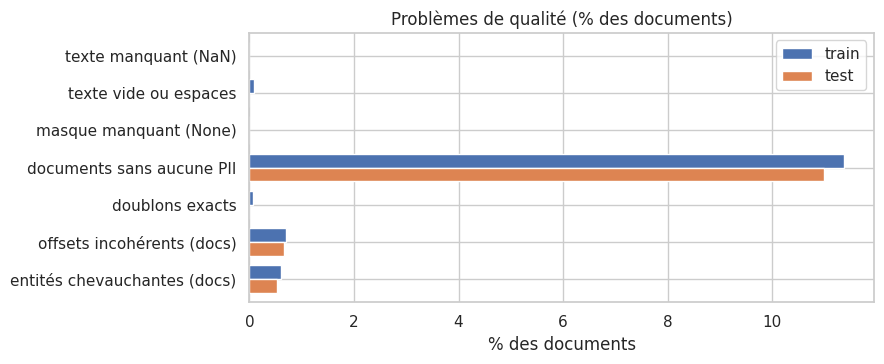

In [30]:
# --- Aperçu du sous-ensemble français ---
norm = lambda l: re.sub(r"\d+$", "", l)          # GIVENNAME1/2 -> GIVENNAME (comme au §4)
print(f"Train FR : {train_full.shape[0]:,} lignes | Test FR : {test_df.shape[0]:,} lignes")
display(train_full[["source_text", "privacy_mask"]].head(3))

# --- Qualité / valeurs manquantes ---
def quality_report(d):
    txt = d["source_text"]
    return pd.Series({
        "texte manquant (NaN)": txt.isna().sum(),
        "texte vide ou espaces": (txt.fillna("").str.strip() == "").sum(),
        "masque manquant (None)": d["privacy_mask"].isna().sum(),
        "documents sans aucune PII": (d["entities"].map(len) == 0).sum(),
        "doublons exacts": txt.duplicated().sum(),
        "offsets incohérents (docs)": sum(any(t[e["start"]:e["end"]] != e["value"] for e in ents) for t, ents in zip(txt.fillna(""), d["entities"])),
        "entités chevauchantes (docs)": sum(any(a["end"] > b["start"] for a, b in zip(ents, ents[1:])) for ents in d["entities"]),
    })
qual = pd.DataFrame({"train": quality_report(train_full), "test": quality_report(test_df)})
qual_pct = 100 * qual / pd.Series({"train": len(train_full), "test": len(test_df)})
display(qual.astype(int).join(qual_pct.round(2), rsuffix=" (%)"))

ax = qual_pct.plot(kind="barh", figsize=(9, 3.8), width=0.75, title="Problèmes de qualité (% des documents)")
ax.invert_yaxis(); ax.set_xlabel("% des documents"); plt.tight_layout(); plt.show()

**Interprétation.**

- Le dataset contient 31 447 lignes pour l’entraînement et 8 413 lignes pour le test, ce qui fournit un volume important de données.
- seulement 25 textes vides dans le train (0,08 %) et aucun texte manquant.
- Environ 11 % des documents ne contiennent aucune PII dans le train et le test. 
- Les doublons exacts sont très rares (0,07 %) dans le train et aucun dans le test).
- Les offsets incohérents et les entités chevauchantes restent minoritaires (moins de 1 %) .

## 3. Exploration (EDA)
1. Répartition des langues · 2. Volumétrie · 3. Types de PII · 4. Forme des valeurs · 5. Structure des documents · 6. Co-occurrences · 7. Train vs test · 8. Contrôles de qualité

### 3.1 Répartition des langues
Le dataset est **multilingue** ; on ne garde que le français (`LANG_PREFIX`). 

,train,validation,total,% du corpus
French,31447,8413,39860,17.7
German,29976,8120,38096,16.9
English,29908,7946,37854,16.8
Italian,29066,7976,37042,16.4
Spanish,28847,7816,36663,16.3
Dutch,28433,7457,35890,15.9


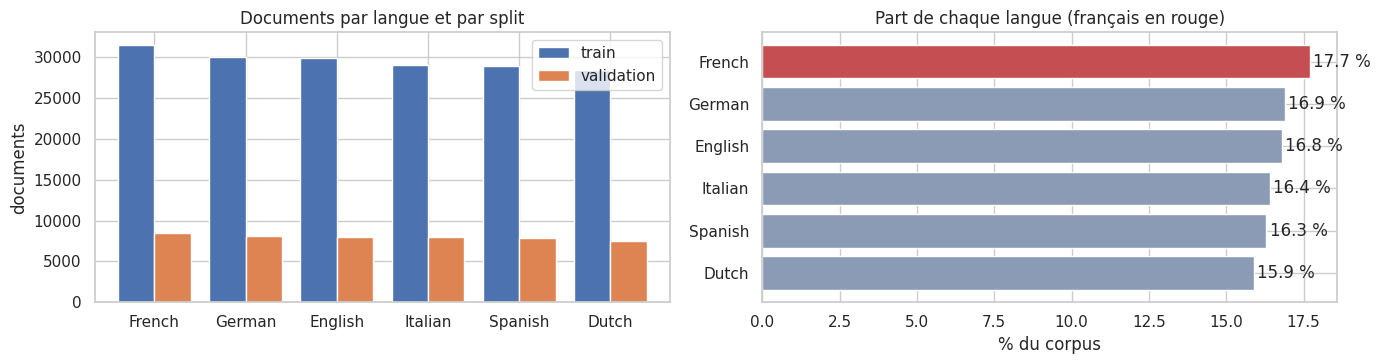

In [31]:
# Répartition des langues du dataset brut (avant filtrage sur le français)
splits = list(raw.keys())
lang_counts = pd.DataFrame({s: pd.Series(list(raw[s]["language"])).value_counts() for s in splits}).fillna(0).astype(int)
lang_counts["total"] = lang_counts.sum(axis=1)
lang_counts["% du corpus"] = (100 * lang_counts["total"] / lang_counts["total"].sum()).round(1)
lang_counts = lang_counts.sort_values("total", ascending=False)
display(lang_counts)

is_fr = lambda l: str(l).strip().lower().startswith(LANG_PREFIX)
pal = {l: "#C44E52" if is_fr(l) else "#8C9BB5" for l in lang_counts.index}   # français en rouge

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
lang_counts[splits].plot(kind="bar", ax=ax[0], width=0.8, rot=0, title="Documents par langue et par split")
ax[0].set_ylabel("documents"); ax[0].set_xlabel("")
ax[1].barh(lang_counts.index, lang_counts["% du corpus"], color=[pal[l] for l in lang_counts.index])
ax[1].invert_yaxis(); ax[1].set_xlabel("% du corpus"); ax[1].set_title("Part de chaque langue (français en rouge)")
for y, v in enumerate(lang_counts["% du corpus"]): ax[1].text(v + 0.1, y, f"{v:.1f} %", va="center")
plt.tight_layout(); plt.show()

**Interprétation.** Les six langues pèsent chacune entre **15,9 % et 17,7 %** .

 Nous avons choisi de nous concentrer sur le français, afin d'adapter l'étude à notre objectif et d'assurer une analyse cohérente du corpus.

### 3.2 Types de PII


,n,n_unique,median_chars,% entités,% documents,ratio_unique
type,,,,,,
TIME,15293,3542,4.0,7.18,31.85,0.23
LASTNAME,13594,12196,7.0,6.38,20.02,0.90
GIVENNAME,11112,9419,6.0,5.21,17.15,0.85
USERNAME,10635,10100,12.0,4.99,19.68,0.95
IDCARD,10196,9820,9.0,4.78,19.04,0.96
EMAIL,10179,9308,20.0,4.78,20.22,0.91
BOD,9986,8687,11.0,4.69,19.45,0.87
PASSPORT,9883,9695,9.0,4.64,18.95,0.98
SOCIALNUMBER,9853,9703,16.0,4.62,19.87,0.98


25 types (labels numérotés fusionnés) | rapport classe la plus fréquente / la plus rare : 3823


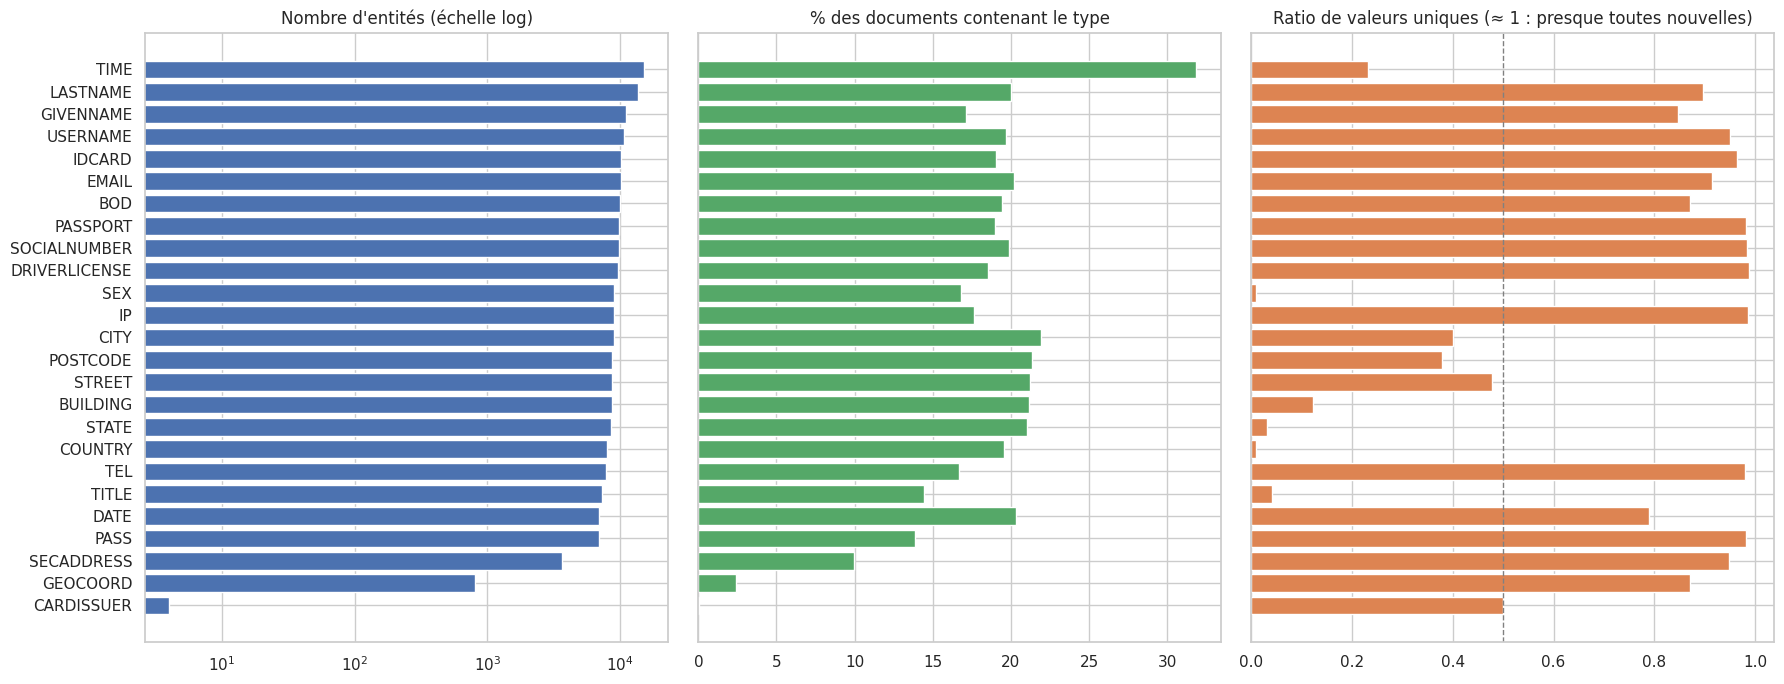

,type,label,n
0,GIVENNAME,GIVENNAME1,8813
1,GIVENNAME,GIVENNAME2,2299
2,LASTNAME,LASTNAME1,10302
3,LASTNAME,LASTNAME2,2468
4,LASTNAME,LASTNAME3,824


In [34]:
ent_df = pd.DataFrame([
    {"doc": i, "label": e["label"], "type": norm(e["label"]), "value": e["value"],
     "n_chars": e["end"] - e["start"], "rel_pos": e["start"] / max(len(t), 1)}
    for i, (t, ents) in enumerate(zip(train_full["source_text"], train_full["entities"])) for e in ents])

by_type = ent_df.groupby("type").agg(n=("value", "size"), n_docs=("doc", "nunique"),
                                     n_unique=("value", "nunique"), median_chars=("n_chars", "median"))
by_type["% entités"]   = 100 * by_type["n"] / by_type["n"].sum()
by_type["% documents"] = 100 * by_type["n_docs"] / len(train_full)
by_type["ratio_unique"] = by_type["n_unique"] / by_type["n"]
by_type = by_type.sort_values("n", ascending=False)
order = by_type.index.tolist()
display(by_type.drop(columns="n_docs").round(2))
print(f"{len(order)} types (labels numérotés fusionnés) | rapport classe la plus fréquente / la plus rare : {by_type['n'].max() / by_type['n'].min():.0f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
ax[0].barh(order, by_type["n"], color="#4C72B0");             ax[0].set_xscale("log"); ax[0].set_title("Nombre d'entités (échelle log)")
ax[1].barh(order, by_type["% documents"], color="#55A868");   ax[1].set_title("% des documents contenant le type")
ax[2].barh(order, by_type["ratio_unique"], color="#DD8452");  ax[2].axvline(0.5, color="grey", ls="--", lw=1)
ax[2].set_title("Ratio de valeurs uniques (≈ 1 : presque toutes nouvelles)")
ax[0].invert_yaxis(); plt.tight_layout(); plt.show()

# Labels numérotés (positionnels) fusionnés en un seul type
display(ent_df[ent_df["label"] != ent_df["type"]].groupby(["type", "label"]).size().rename("n").reset_index())

**Interprétation.**
- **25 types de PII** avec des fréquences très différentes.
- Les identifiants sont souvent uniques → importance de la forme et du contexte.
- Les noms/prénoms sont plus difficiles car ils sont très variés ,
 Après fusion, on va passer par exemple de : GIVENNAME1, GIVENNAME2, LASTNAME1, LASTNAME2, LASTNAME3 à seulement : GIVENNAME, LASTNAME

## 4. Preprocessing

| Choix | Justification |
|---|---|
| Casse, ponctuation, chiffres **conservés** | La majuscule signale les noms propres ; les PII structurées *sont* des chiffres et de la ponctuation. |
| Pas de stopwords / lemmatisation / normalisation Unicode | Détruisent le contexte et décalent les offsets nécessaires au masquage. |
| Fusion `GIVENNAME1/2 → GIVENNAME`, `LASTNAME1/2/3 → LASTNAME` | Le numéro est positionnel et inutile pour anonymiser. |
| Doublons supprimés du train | Évite de surestimer les scores. |
| Les données sont réparties en 90 % pour l’entraînement et 10 % pour la validation| Le test reste indépendant et n’est utilisé qu’à l’évaluation finale. |
| Tokenisation classique choisie **sur les données** | |

In [35]:
def normalize_label(l):
    return re.sub(r"\d+$", "", l) if MERGE_LABELS else l

def gold_spans(text, ents):
    """Labels normalisés ; fusion des spans adjacents de même type séparés par des espaces uniquement."""
    spans = [[e["start"], e["end"], normalize_label(e["label"])] for e in ents]
    if not MERGE_LABELS: return [tuple(s) for s in spans]
    out = []
    for s in spans:
        if out and out[-1][2] == s[2] and text[out[-1][1]:s[0]].strip() == "": out[-1][1] = s[1]
        else: out.append(s)
    return [tuple(s) for s in out]

train_full = train_full.drop_duplicates("source_text").reset_index(drop=True)
for d in (train_full, test_df):
    d["spans"] = [gold_spans(t, ents) for t, ents in zip(d["source_text"], d["entities"])]

idx = np.random.RandomState(SEED).permutation(len(train_full))
n_dev = int(DEV_FRACTION * len(train_full))
keep = ["source_text", "spans"]
dev_df   = train_full.iloc[idx[:n_dev]][keep].reset_index(drop=True)
train_df = train_full.iloc[idx[n_dev:]][keep].reset_index(drop=True)
test_df  = test_df[keep].reset_index(drop=True)

LABELS = sorted({l for spans in train_df["spans"] for _, _, l in spans})
print(f"{len(LABELS)} types de PII : {LABELS}")
print(f"train={len(train_df):,} | dev={len(dev_df):,} | test={len(test_df):,}")

25 types de PII : ['BOD', 'BUILDING', 'CARDISSUER', 'CITY', 'COUNTRY', 'DATE', 'DRIVERLICENSE', 'EMAIL', 'GEOCOORD', 'GIVENNAME', 'IDCARD', 'IP', 'LASTNAME', 'PASS', 'PASSPORT', 'POSTCODE', 'SECADDRESS', 'SEX', 'SOCIALNUMBER', 'STATE', 'STREET', 'TEL', 'TIME', 'TITLE', 'USERNAME']
train=28,282 | dev=3,142 | test=8,413


**Interprétation.** Après suppression des doublons, le corpus comprend 28 282 documents pour l’entraînement, 3 142 pour le développement et 8 413 pour le test.

### 4.1 Augmentation (train uniquement)
Le corpus étant principalement composé de formulaires, nous ajoutons des phrases plus naturelles pour mieux représenter les situations réelles, en utilisant uniquement des données du train afin d’éviter toute fuite de données.

In [36]:
POOL = defaultdict(list)
for t, sp in zip(train_df["source_text"], train_df["spans"]):
    for s, e, l in sp:
        v = t[s:e]
        if "\n" not in v and len(v) <= 40: POOL[l].append(v)
POOL = {l: sorted(set(v)) for l, v in POOL.items()}

TEMPLATES = [
    "Bonjour, je m'appelle {GIVENNAME} {LASTNAME} et j'habite au {BUILDING} {STREET}, {POSTCODE} {CITY}. Mon numéro est le {TEL}.",
    "Veuillez envoyer la facture à {EMAIL} avant le {DATE}, merci.",
    "Le patient {TITLE} {LASTNAME}, né le {BOD}, s'est connecté depuis l'adresse IP {IP}.",
    "Merci de contacter {GIVENNAME} {LASTNAME} au {TEL} ou par mail à {EMAIL}.",
    "Rendez-vous confirmé le {DATE} à {TIME} au {BUILDING} {STREET} à {CITY}.",
    "Mon identifiant est {USERNAME} et mon mot de passe est {PASS}.",
    "Je vis à {CITY} ({STATE}, {COUNTRY}) depuis plusieurs années.",
    "{TITLE} {LASTNAME} a signalé une connexion suspecte depuis {IP} à {TIME}.",
    "Numéro de sécurité sociale : {SOCIALNUMBER}. Passeport : {PASSPORT}.",
    "Cher {TITLE} {LASTNAME}, votre colis sera livré au {BUILDING} {STREET}, {POSTCODE} {CITY}.",
    "Pièce d'identité n° {IDCARD}, permis {DRIVERLICENSE}, délivrés à {GIVENNAME} {LASTNAME}.",
    "Aucune donnée personnelle ici : la réunion de demain porte sur le budget de l'équipe.",
]
SLOT = re.compile(r"\{(\w+)\}")
USABLE = [t for t in TEMPLATES if all(l in POOL for l in SLOT.findall(t))]

def fill(template, rng):
    text, spans, pos = "", [], 0
    for m in SLOT.finditer(template):
        text += template[pos:m.start()]
        val = rng.choice(POOL[m.group(1)])
        spans.append((len(text), len(text) + len(val), m.group(1))); text += val; pos = m.end()
    return text + template[pos:], spans

if USE_AUGMENTATION:
    rng = random.Random(SEED)
    aug = [fill(rng.choice(USABLE), rng) for _ in range(N_AUG)]
    aug_df = pd.DataFrame({"source_text": [a for a, _ in aug], "spans": [b for _, b in aug]})
    train_df = pd.concat([train_df, aug_df], ignore_index=True)
    print(f"+{len(aug_df):,} documents augmentés -> train = {len(train_df):,} ({len(USABLE)} modèles de phrases)")
    print(aug_df["source_text"].iloc[0])

+4,000 documents augmentés -> train = 32,282 (12 modèles de phrases)
Pièce d'identité n° E2405584032814, permis 0942995667, délivrés à Rimsha Kachuwaire.


**Interprétation.** **4 000 phrases en prose** sont ajoutées (train : 28 282 → **32 282**, soit +14 %) à partir de 12 modèles de phrases. Les valeurs sont tirées du train, donc sans fuite vers le dev ou le test. 

### 4.2 Tokenisation et génération des labels BIO
Cette étape compare deux tokenisations, sélectionne celle qui reconstruit le mieux les entités, puis génère les labels BIO pour l’entraînement du modèle.

**Tokenisation simple :** découpe le texte en mots et caractères spéciaux.

Exemple : flen@gmail.com → flen, @, gmail, ., com

**Tokenisation fine :** conserve certaines informations structurées, comme les e-mails, adresses IP, dates ou numéros, autant que possible dans un même token.

Exemple : flen@gmail.com → flen@gmail.com

In [37]:
TOKEN_RES = {  # "fin" garde e-mails, IP, dates, numéros comme un seul token ; "simple" = v1
    "fin":    re.compile(r"\w+(?:[.\-@+/]\w+)*|[^\w\s]"),
    "simple": re.compile(r"\w+|[^\w\s]"),
}

def tokenize_with(regex, text):
    return [(m.group(), m.start(), m.end()) for m in regex.finditer(text)]

def bio_tags(tokens, spans):
    """Un token appartient à un span s'il le chevauche ; B- pour le premier token du span."""
    tags = ["O"] * len(tokens)
    for s, e, l in spans:
        first = True
        for i, (_, ts, te) in enumerate(tokens):
            if ts < e and te > s:
                tags[i] = ("B-" if first else "I-") + l; first = False
    return tags

def tags_to_spans(tokens, tags):
    """Reconstruit des spans caractères (start, end, label) depuis une séquence BIO/IO."""
    spans, cur = [], None
    for (_, ts, te), t in zip(tokens, tags):
        if t == "O":
            if cur: spans.append(tuple(cur)); cur = None
            continue
        prefix, lab = t.split("-", 1)
        if cur and lab == cur[2] and prefix == "I": cur[1] = te
        else:
            if cur: spans.append(tuple(cur))
            cur = [ts, te, lab]
    if cur: spans.append(tuple(cur))
    return spans

def recon_rate(regex, df, n=2000):
    """Part des documents dont les spans gold sont exactement reconstruits depuis les tokens (borne haute d'un modèle token-level)."""
    sub = df.sample(min(n, len(df)), random_state=SEED); ok = 0
    for t, sp in zip(sub["source_text"], sub["spans"]):
        tok = tokenize_with(regex, t)
        ok += set(tags_to_spans(tok, bio_tags(tok, sp))) == set(sp)
    return ok / len(sub)

rates = {k: recon_rate(r, train_df) for k, r in TOKEN_RES.items()}
TOKEN_RE = TOKEN_RES[max(rates, key=rates.get)]
print("Reconstruction des spans par tokenisation :", {k: f"{v:.2%}" for k, v in rates.items()}, "->", max(rates, key=rates.get))

def tokenize_with_offsets(text): return tokenize_with(TOKEN_RE, text)

for d in (train_df, dev_df, test_df):
    d["tokens"] = d["source_text"].map(tokenize_with_offsets)
    d["tags"] = [bio_tags(tok, sp) for tok, sp in zip(d["tokens"], d["spans"])]

Reconstruction des spans par tokenisation : {'fin': '98.70%', 'simple': '98.75%'} -> simple


**Interprétation.** la méthode « fine » reconstruit correctement les entités dans 98,70 % des documents, tandis que la méthode « simple » atteint 98,75 %. La tokenisation simple a donc été retenue.

---
# IV. Méthodologie

## Formulation de la  tâche de **classification de tokens**
Le modèle doit classer chaque token du texte pour déterminer s'il ne contient aucune PII (O) ou s'il appartient à une PII (B-TYPE ou I-TYPE).
Avec 25 types de PII, cela donne 51 classes : 1 × O + 25 × B + 25 × I.

Ensuite, les tokens appartenant à une même entité sont regroupés pour retrouver sa position dans le texte, puis l'entité est remplacée par [TYPE].

## Chaîne de traitement

Texte brut → Tokenisation → Classification → BIO → Reconstruction → Masquage 

- Tokenisation : le texte est découpé en tokens et on garde leur position dans le texte (offsets).

- Classification des tokens : le modèle détermine si chaque token appartient à une PII.

- Étiquettes BIO : chaque token reçoit une étiquette (O, B-TYPE, I-TYPE).

- Reconstruction des spans : les tokens d'une même PII sont regroupés pour retrouver l'entité complète.

- Nettoyage des bornes : on corrige les espaces ou caractères inutiles autour de l'entité (trim_spans).

- Masquage : l'entité détectée est remplacée par son type, par exemple [EMAIL], [GIVENNAME], etc.


## Deux approches comparées
| | Approche 1 : classique | Approche 2 : Transformer |
|---|---|---|
| Représentation | TF-IDF + mots + caractéristiques du texte | Représentations de `xlm-roberta-base` |
| Modèle | SVM linéaire , schéma IO | XLM-RoBERTa avec classification des tokens |
| Réglage | Réglage de alpha| Réglage du nombre d’époques + seuil |





## 5. Protocole d'évaluation

**Objectif principal : minimiser les fuites de données personnelles tout en limitant les faux masquages.**

-Precision → éviter les faux masquages

-Recall → détecter un maximum de données sensibles

-F1-score → équilibre Precision / Recall

-F1 entité exact → vérifier la détection complète des entités

-Taux de fuite → mesurer les données sensibles laissées visibles


**Pourquoi pas uniquement l’Accuracy ?**

Les données personnelles sont minoritaires dans un texte → un modèle peut avoir une bonne accuracy tout en laissant passer des informations sensibles.




In [ ]:
# ---------- Utilitaires sur les spans ----------
STRUCTURED = {"EMAIL", "IP", "TEL", "DATE", "BOD", "TIME", "POSTCODE", "SOCIALNUMBER", "IDCARD", "PASSPORT", "DRIVERLICENSE"}
RAW        = {"PASS", "USERNAME", "GEOCOORD"}      # la ponctuation en bordure fait partie de la valeur (ex. mot de passe "{]qN…")
PUNCT      = ",;:!?()[]{}\"'«»“”<>"

def _strip(text, s, e, label):
    while s < e and text[s].isspace(): s += 1
    while e > s and text[e - 1].isspace(): e -= 1
    if label in RAW: return s, e
    if label in STRUCTURED:                        # seulement une ponctuation finale de phrase
        if e > s and text[e - 1] in ".,;" and (e == len(text) or text[e].isspace()): e -= 1
        return s, e
    while s < e and text[s] in PUNCT: s += 1       # types textuels : on retire ponctuation collée et point final
    while e > s and (text[e - 1] in PUNCT or (text[e - 1] == "." and (e == len(text) or text[e].isspace()))): e -= 1
    return s, e

def trim_spans(text, spans):
    """Nettoie les bornes selon le type (v1 rognait à tort les mots de passe) ; un span textuel ne traverse pas les retours à la ligne."""
    out = []
    for s, e, l in spans:
        pieces = [(s, e)] if (l in RAW or l in STRUCTURED) else [(s + m.start(), s + m.end()) for m in re.finditer(r"[^\n]+", text[s:e])]
        for a, b in pieces:
            a, b = _strip(text, a, b, l)
            if a < b: out.append((a, b, l))
    return out

def merge_adjacent(text, spans):
    """Fusionne les spans contigus de même type séparés par des espaces (pas par un retour à la ligne)."""
    out = []
    for s, e, l in sorted(spans):
        gap = text[out[-1][1]:s] if out else ""
        if out and out[-1][2] == l and gap.strip() == "" and "\n" not in gap:
            out[-1] = (out[-1][0], max(out[-1][1], e), l)
        else: out.append((s, e, l))
    return out

def mask_text(text, spans, fmt="[{}]"):
    out, last = [], 0
    for s, e, l in sorted(spans):
        if s < last: continue
        out += [text[last:s], fmt.format(l)]; last = e
    return "".join(out + [text[last:]])

# ---------- Types grossiers (vue PER/LOC/DATE) ----------
NER_TYPES = ["PER", "LOC", "ORG", "MISC", "DATE"]
COARSE_MAP = {"GIVENNAME": "PER", "LASTNAME": "PER",
              "CITY": "LOC", "STREET": "LOC", "STATE": "LOC", "COUNTRY": "LOC", "BUILDING": "LOC", "SECADDRESS": "LOC",
              "DATE": "DATE", "BOD": "DATE", "CARDISSUER": "ORG"}
COVERED = ["PER", "LOC", "DATE"]      # types communs au dataset et au NER (ORG : 2 exemples, ignoré)

def coarse_of(label):
    return label if label in NER_TYPES else COARSE_MAP.get(re.sub(r"\d+$", "", label), "AUTRE")

def to_coarse(text, spans, keep=COVERED):
    return [(s, e, l) for s, e, l in merge_adjacent(text, [(s, e, coarse_of(l)) for s, e, l in spans]) if l in keep]

# ---------- Métriques ----------
def span_prf(gold, pred, labels=None, min_support=30):
    """gold, pred : listes (par document) de (start, end, label). Match exact. Retourne micro, macro, macro (classes >= min_support), par classe."""
    tp, fp, fn = Counter(), Counter(), Counter()
    for g, p in zip(gold, pred):
        g, p = set(g), set(p)
        for s in g & p: tp[s[2]] += 1
        for s in p - g: fp[s[2]] += 1
        for s in g - p: fn[s[2]] += 1
    labels = labels or sorted(set(tp) | set(fp) | set(fn))
    rows = []
    for l in labels:
        P = tp[l] / (tp[l] + fp[l]) if tp[l] + fp[l] else 0.0
        R = tp[l] / (tp[l] + fn[l]) if tp[l] + fn[l] else 0.0
        rows.append({"label": l, "precision": P, "recall": R, "f1": 2 * P * R / (P + R) if P + R else 0.0, "support": tp[l] + fn[l]})
    per = pd.DataFrame(rows).set_index("label")
    TP, FP, FN = sum(tp.values()), sum(fp.values()), sum(fn.values())
    P = TP / (TP + FP) if TP + FP else 0.0; R = TP / (TP + FN) if TP + FN else 0.0
    micro = {"precision": P, "recall": R, "f1": 2 * P * R / (P + R) if P + R else 0.0}
    macro = lambda m: per[m][["precision", "recall", "f1"]].mean().to_dict()
    return micro, macro(per["support"] > 0), macro(per["support"] >= min_support), per

def char_masking_scores(texts, gold, pred):
    """Précision / rappel de masquage par caractère (type ignoré, espaces ignorés) + taux de fuite global et par type."""
    tp = fp = fn = n_ent = n_leak = 0; ent_by, leak_by = Counter(), Counter()
    for t, g, p in zip(texts, gold, pred):
        gm, pm = np.zeros(len(t), bool), np.zeros(len(t), bool)
        for x in g: gm[x[0]:x[1]] = True
        for x in p: pm[x[0]:x[1]] = True
        ns = np.array([not c.isspace() for c in t], bool) if len(t) else np.zeros(0, bool)
        tp += (gm & pm & ns).sum(); fp += (~gm & pm & ns).sum(); fn += (gm & ~pm & ns).sum()
        for s, e, l in g:
            n_ent += 1; ent_by[l] += 1
            if not pm[s:e][ns[s:e]].all(): n_leak += 1; leak_by[l] += 1
    P = tp / (tp + fp) if tp + fp else 0.0; R = tp / (tp + fn) if tp + fn else 0.0
    res = {"char_precision": P, "char_recall": R, "char_f1": 2 * P * R / (P + R) if P + R else 0.0, "leak_rate": n_leak / max(n_ent, 1)}
    return res, pd.Series({l: leak_by[l] / ent_by[l] for l in ent_by}, name="leak_rate")

def char_f2(res):
    """F2 (rappel pondéré 2x) : critère « vie privée » pour régler le seuil de décision."""
    P, R = res["char_precision"], res["char_recall"]
    return 5 * P * R / (4 * P + R) if 4 * P + R else 0.0

def relaxed_prf(gold, pred):
    """Match relâché : un span est correct s'il chevauche un span de même type (conventions de bornes différentes)."""
    ov = lambda a, b: a[2] == b[2] and min(a[1], b[1]) > max(a[0], b[0])
    tg = ng = tp = npred = 0
    for g, p in zip(gold, pred):
        ng += len(g); npred += len(p)
        tg += sum(any(ov(x, q) for q in p) for x in g)
        tp += sum(any(ov(q, x) for x in g) for q in p)
    P = tp / npred if npred else 0.0; R = tg / ng if ng else 0.0
    return {"precision": P, "recall": R, "f1": 2 * P * R / (P + R) if P + R else 0.0}

---
# V. Implémentation

L'implémentation repose sur **scikit-learn** [16] pour l'approche classique et sur **Hugging Face Transformers** [17] pour le Transformer. 



## 6. Approche classique : TF-IDF + modèle linéaire

**Représentation :**
Chaque token est représenté à partir de ses caractères et des mots qui l’entourent. On utilise également des caractéristiques simples comme la longueur, les majuscules ou la présence de chiffres.

**Modèle :**
Un SVM linéaire (SGDClassifier) est utilisé pour classer chaque token.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import SGDClassifier

def shape(w):
    s = re.sub(r"[A-ZÀ-Ý]", "X", w); s = re.sub(r"[a-zà-ÿ]", "x", s); s = re.sub(r"\d", "d", s)
    return re.sub(r"(.)\1{2,}", r"\1\1", s)

def doc_features(tokens):
    words = [t for t, _, _ in tokens]; n = len(words)
    cur, ctx, hand = [], [], []
    for i, w in enumerate(words):
        cur.append(w)
        ctx.append(" ".join([f"p2_{words[i-2].lower()}" if i >= 2 else "p2_<s>",
                             f"p1_{words[i-1].lower()}" if i >= 1 else "p1_<s>",
                             f"n1_{words[i+1].lower()}" if i + 1 < n else "n1_</s>",
                             f"n2_{words[i+2].lower()}" if i + 2 < n else "n2_</s>"]))
        hand.append({"shape": shape(w), "is_title": w.istitle(), "is_upper": w.isupper(), "is_digit": w.isdigit(),
                     "has_digit": any(c.isdigit() for c in w), "len": min(len(w), 12), "first": i == 0,
                     "p1_shape": shape(words[i-1]) if i else "<s>", "n1_shape": shape(words[i+1]) if i + 1 < n else "</s>"})
    return cur, ctx, hand

def featurize(tokens_list):
    cur, ctx, hand = [], [], []
    for tokens in tokens_list:
        c, x, h = doc_features(tokens); cur += c; ctx += x; hand += h
    return cur, ctx, hand

io_tags = lambda tags: [t if t == "O" else t.split("-", 1)[1] for t in tags]

t0 = time.time()
vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=3, max_features=200_000, sublinear_tf=True, lowercase=False)
vec_ctx  = TfidfVectorizer(analyzer=str.split, min_df=3, max_features=100_000, sublinear_tf=True, lowercase=False)
vec_hand = DictVectorizer()

cur_tr, ctx_tr, hand_tr = featurize(train_df["tokens"])
y_tr = np.array([t for tags in train_df["tags"] for t in io_tags(tags)])
X_tr = sparse.hstack([vec_char.fit_transform(cur_tr), vec_ctx.fit_transform(ctx_tr), vec_hand.fit_transform(hand_tr)]).tocsr()
del cur_tr, ctx_tr, hand_tr
print(f"{X_tr.shape[0]:,} tokens d'entraînement ({len(train_df):,} documents), {X_tr.shape[1]:,} traits ({time.time() - t0:.0f}s)")

def svm_predict_factory(clf):
    def predict(texts):
        toks = [tokenize_with_offsets(t) for t in texts]
        cur, ctx, hand = featurize(toks)
        y = clf.predict(sparse.hstack([vec_char.transform(cur), vec_ctx.transform(ctx), vec_hand.transform(hand)]).tocsr())
        out, k = [], 0
        for tok in toks:
            tags = y[k:k + len(tok)]; k += len(tok)
            out.append(tags_to_spans(tok, ["O" if t == "O" else "I-" + t for t in tags]))
        return out
    return predict

In [41]:
# Réglage d'alpha sur le dev (sous-ensemble d'entraînement pour aller vite)
doc_len = train_df["tokens"].map(len).values
tune_docs = np.zeros(len(train_df), bool)
tune_docs[np.random.RandomState(SEED).choice(len(train_df), min(N_TUNE_DOCS, len(train_df)), replace=False)] = True
rows_mask = np.repeat(tune_docs, doc_len)
dev_small = dev_df.sample(min(3000, len(dev_df)), random_state=SEED)
dev_texts, dev_gold = list(dev_small["source_text"]), list(dev_small["spans"])

best = None
for alpha in ALPHAS:
    clf = SGDClassifier(loss="hinge", alpha=alpha, max_iter=50, tol=1e-4, n_jobs=-1, random_state=SEED).fit(X_tr[rows_mask], y_tr[rows_mask])
    f1 = span_prf(dev_gold, svm_predict_factory(clf)(dev_texts))[0]["f1"]
    print(f"alpha={alpha:g}  F1 entité (dev) = {f1:.4f}")
    if best is None or f1 > best[0]: best = (f1, alpha)
best_alpha = best[1]
print(f"-> alpha retenu : {best_alpha:g} ; ré-entraînement sur tout le train…")
t0 = time.time()
svm_clf = SGDClassifier(loss="hinge", alpha=best_alpha, max_iter=50, tol=1e-4, n_jobs=-1, random_state=SEED).fit(X_tr, y_tr)
print(f"Entraînement final : {time.time() - t0:.0f}s")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


alpha=1e-07  F1 entité (dev) = 0.5741


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


alpha=1e-06  F1 entité (dev) = 0.6473
alpha=1e-05  F1 entité (dev) = 0.6146
-> alpha retenu : 1e-06 ; ré-entraînement sur tout le train…
Entraînement final : 158s


**Interprétation.**

Nous avons testé trois valeurs de α :

10⁻⁷ → F1 = 0,574
10⁻⁶ → F1 = 0,647
10⁻⁵ → F1 = 0,615

La meilleure valeur est donc α = 10⁻⁶.


In [42]:
svm_predict = svm_predict_factory(svm_clf)
run("TF-IDF + SVM", svm_predict)
show_result("TF-IDF + SVM")

# Interprétabilité : traits les plus positifs par type
feat_names = np.concatenate([["char:" + f for f in vec_char.get_feature_names_out()],
                             ["ctx:" + f for f in vec_ctx.get_feature_names_out()],
                             ["hand:" + f for f in vec_hand.get_feature_names_out()]])
for lab in [l for l in ["EMAIL", "GIVENNAME", "CITY", "TEL", "DATE"] if l in svm_clf.classes_]:
    w = svm_clf.coef_[list(svm_clf.classes_).index(lab)]
    print(f"{lab:10s}", ", ".join(feat_names[np.argsort(w)[-8:][::-1]]))

,char_P,char_R,fuite,char_R (PII couvertes),F1 grossier strict,F1 grossier relâché,P,R,F1,F1 macro,F1 macro (≥30),ms/doc
test,0.952,0.960,0.093,0.941,0.833,0.914,0.626,0.758,0.686,0.648,0.675,3.032
ood,0.988,0.816,0.289,0.824,0.647,0.970,0.455,0.526,0.488,0.478,NaN,NaN


EMAIL      hand:shape=xx, hand:n1_shape=@, hand:shape=@, hand:has_digit, hand:shape=x, hand:p1_shape=@, hand:shape=XX, hand:shape=Xxx
GIVENNAME  hand:shape=xx, hand:shape=Xxx, ctx:p2_délivrés, hand:shape=-, char:a , hand:shape=Xx, hand:shape=., hand:shape=/
CITY       hand:shape=xx, hand:shape=x, hand:is_title, hand:shape=-, hand:shape=(, hand:shape=', ctx:n1_arrondissement, ctx:p2_ville
TEL        hand:shape=xx, hand:shape=+, hand:p1_shape=+, ctx:p2_+, hand:is_digit, hand:shape=-, hand:shape=., hand:has_digit
DATE       char: 20, hand:shape=xx, ctx:n2_à, ctx:p2_date, char:20, hand:has_digit, ctx:n2_nheure, ctx:n2_merci


**Interprétation.**

**Test :** le modèle obtient un F1 de 0,686 et un rappel de 0,960. Il détecte donc la majorité des informations sensibles, mais peut se tromper sur leurs limites ou leur type. Le taux de fuite reste de 9,3 %.

**Hors-distribution :** le F1 descend à 0,488 et le taux de fuite augmente à 28,9 %. Le modèle fonctionne donc moins bien sur des textes différents de ceux utilisés pour l’apprentissage.

**Traits importants :** le modèle utilise surtout la forme des tokens : @ pour les emails, + pour les téléphones, les majuscules pour les noms de villes, etc.



## 7. Transformer fine-tuné (classification de tokens)

**Pourquoi.**

XLM-RoBERTa utilise le contexte pour mieux identifier les informations sensibles.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForTokenClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimen

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.159016,0.151626,0.892578,0.934774,0.913189
2,0.112516,0.108512,0.931858,0.951739,0.941693
3,0.083932,0.103380,0.931946,0.959492,0.945519
4,0.066608,0.098225,0.936429,0.960808,0.948462


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Durée d'entraînement : 59.6 min


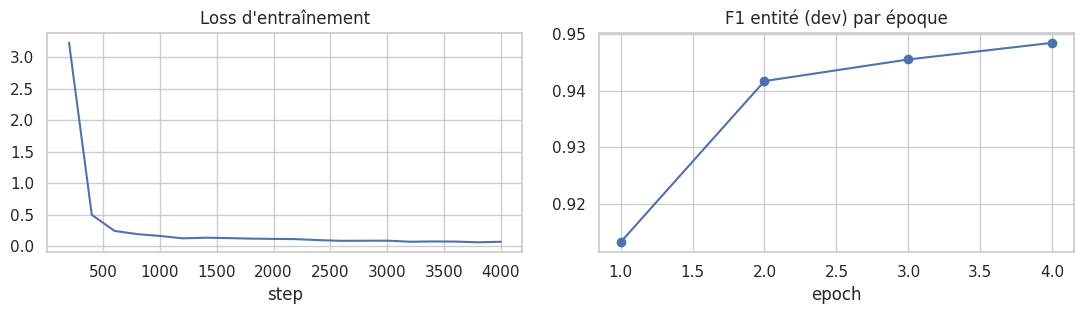

In [44]:
def bio_spans(seq):
    """Spans (label, début, fin) d'une séquence BIO (indices de tokens)."""
    spans, cur = set(), None
    for i, t in enumerate(list(seq) + ["O"]):
        if t == "O" or t.startswith("B-") or (cur and t[2:] != cur[0]):
            if cur: spans.add((cur[0], cur[1], i)); cur = None
        if t.startswith("B-") or (t.startswith("I-") and cur is None): cur = [t[2:], i]
    return spans

def compute_metrics(p):
    logits, labels = p; preds = logits.argmax(-1); tp = fp = fn = 0
    for pr, lb in zip(preds, labels):
        m = lb != -100
        g, q = bio_spans([id2label[i] for i in lb[m]]), bio_spans([id2label[i] for i in pr[m]])
        tp += len(g & q); fp += len(q - g); fn += len(g - q)
    P = tp / (tp + fp) if tp + fp else 0.0; R = tp / (tp + fn) if tp + fn else 0.0
    return {"precision": P, "recall": R, "f1": 2 * P * R / (P + R) if P + R else 0.0}

def make_args(output_dir):
    kw = dict(output_dir=output_dir, learning_rate=LR, num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH_SIZE,
              per_device_eval_batch_size=64, weight_decay=0.01, lr_scheduler_type="linear", eval_strategy="epoch",
              save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1", save_total_limit=1,
              fp16=(device == "cuda"), logging_steps=200, report_to="none", seed=SEED)
    try:    return TrainingArguments(**kw, warmup_ratio=0.1)      # transformers < 5
    except TypeError: return TrainingArguments(**kw, warmup_steps=0.1)   # transformers >= 5 : float < 1 = ratio

model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, num_labels=len(BIO_LABELS), id2label=id2label, label2id=label2id)
trainer = Trainer(model=model, args=make_args("modele-pii-fr"), train_dataset=hf_train, eval_dataset=hf_dev,
                  data_collator=DataCollatorForTokenClassification(tokenizer), compute_metrics=compute_metrics)
t0 = time.time(); trainer.train()
print(f"Durée d'entraînement : {(time.time() - t0) / 60:.1f} min")

hist = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
hist.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax[0], title="Loss d'entraînement", legend=False)
hist.dropna(subset=["eval_f1"]).plot(x="epoch", y=["eval_f1"], ax=ax[1], marker="o", title="F1 entité (dev) par époque", legend=False)
plt.tight_layout(); plt.show()

**Interprétation.**

-La loss diminue fortement au fil des époques, ce qui montre que le modèle apprend efficacement.

-La précision, le rappel et le F1 augmentent progressivement.

-Le F1 passe **de 0,913 à 0,948,** indiquant une bonne performance de détection des entités.

-À la 4ᵉ époque, les performances sont les meilleures, avec **Precision = 93,64 %, Recall = 96,08 % et F1 = 94,85 %.**


### 7.2 Inférence 

**L’inférence** correspond à l’utilisation du modèle entraîné pour faire des prédictions sur de nouvelles données.

On réalise l’inférence finale du modèle Transformer sur les données de test et hors distribution (OOD) .



In [56]:
# Probabilités sur test et OOD (une seule passe du modèle) ; le décodage τ ne relance pas le modèle
texts_t, texts_o = DATASETS["test"][0], DATASETS["ood"][0]
t0 = time.time(); probs_t = token_probs(texts_t); t_tf = time.time() - t0
probs_o = token_probs(texts_o)
print(f"Inférence Transformer sur le test : {t_tf:.0f}s ({1000 * t_tf / len(texts_t):.1f} ms/doc)")

TF_TAU = f"Transformer (τ={TAU})"
register(TF_TAU, {"test": [decode(t, p, TAU) for t, p in zip(texts_t, probs_t)],
                  "ood":  [decode(t, p, TAU) for t, p in zip(texts_o, probs_o)]}, t_tf)
PREDICT[TF_TAU] = lambda texts: [decode(t, p, TAU) for t, p in zip(texts, token_probs(texts))]
show_result(TF_TAU)

Inférence Transformer sur le test : 94s (11.1 ms/doc)


,char_P,char_R,fuite,char_R (PII couvertes),F1 grossier strict,F1 grossier relâché,P,R,F1,F1 macro,F1 macro (≥30),ms/doc
test,0.965,0.994,0.011,0.992,0.951,0.966,0.875,0.956,0.914,0.878,0.915,11.126
ood,0.957,1.000,0.000,1.000,0.788,1.000,0.895,0.895,0.895,0.876,NaN,NaN


**Interprétation.**

Sur le jeu de test, le modèle obtient un F1 entité de 91,4 % et un rappel caractère de 99,4 %, avec seulement 1,1 % de fuite. 

Sur les données OOD, il obtient un F1 de 89,5 % et aucune fuite .

 Le modèle conserve donc des performances proches entre Test et OOD, ce qui indique une bonne généralisation,

---
# VII. Résultats

## 8. Comparaison des approches

,char_P,char_R,fuite,char_R (PII couvertes),F1 grossier strict,F1 grossier relâché,P,R,F1,F1 macro,F1 macro (≥30),ms/doc
modèle,,,,,,,,,,,,
TF-IDF + SVM,0.952000,0.960000,0.093000,0.941000,0.833000,0.914000,0.626000,0.758000,0.686000,0.648000,0.675000,3.032000
Transformer (τ=0.9),0.965000,0.994000,0.011000,0.992000,0.951000,0.966000,0.875000,0.956000,0.914000,0.878000,0.915000,11.126000


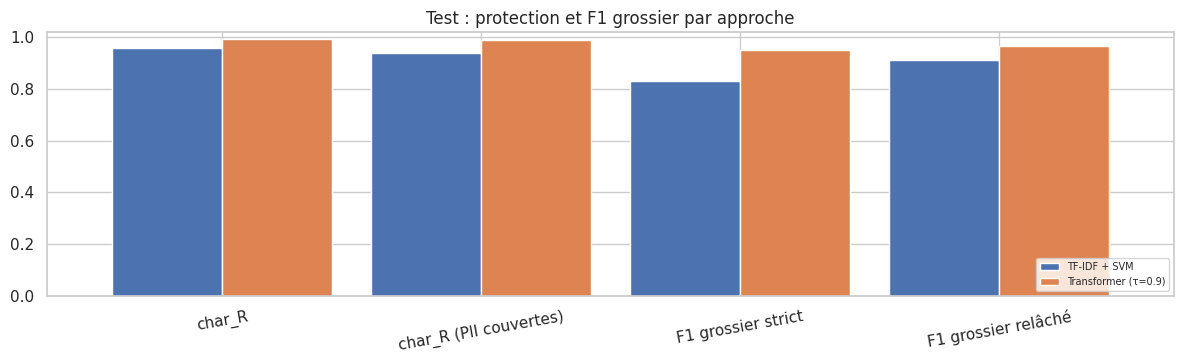

In [57]:
tab = pd.DataFrame(RESULTS["test"].values()).set_index("modèle")
good = [c for c in ["F1", "F1 macro", "F1 macro (≥30)", "char_R", "char_R (PII couvertes)", "F1 grossier strict", "F1 grossier relâché"] if c in tab]
display(tab.round(3).style.background_gradient(cmap="Greens", subset=good).background_gradient(cmap="Reds", subset=["fuite"]))

# Vue d'ensemble : protection effective
key = ["char_R", "char_R (PII couvertes)", "F1 grossier strict", "F1 grossier relâché"]
ax = tab[key].T.plot(kind="bar", figsize=(12, 3.8), width=0.85, title="Test : protection et F1 grossier par approche")
ax.set_ylim(0, 1.02); ax.legend(fontsize=7, loc="lower right"); plt.xticks(rotation=10); plt.tight_layout(); plt.show()

**Transformer :**

-meilleure couverture des PII : 99,2 %

-meilleur rappel caractère : 99,4 %

-meilleur F1 caractère : 97,9 %

-meilleur F1 grossier strict : 95,1 %

-meilleur F1 grossier relâché : 96,6 %

-meilleur F1 macro : 87,8 %

-mais plus lent : 11,126 ms/doc

**TF-IDF + SVM :**

-moins performant sur les métriques de détection

-mais beaucoup plus rapide : 3,032 ms/doc

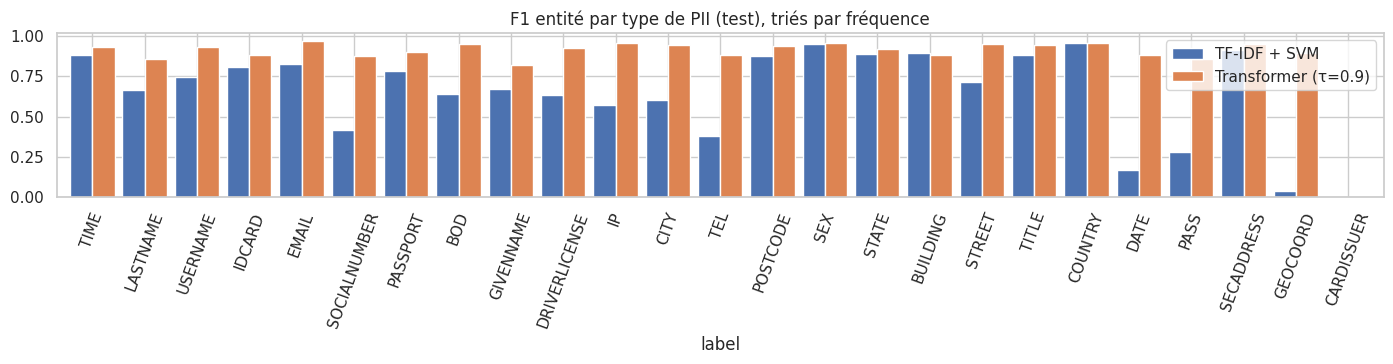

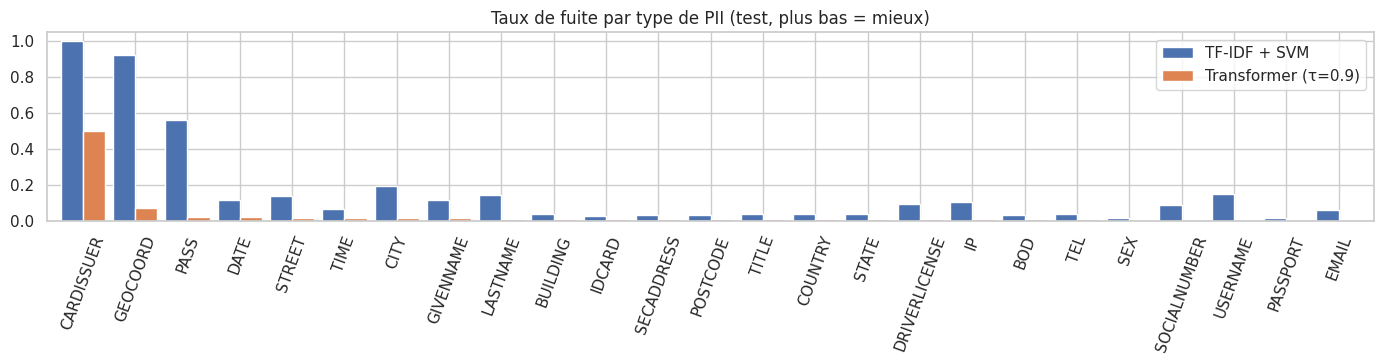

In [58]:
# F1 par type de PII (modèles entraînés sur les types fins) et taux de fuite par type
fine_models = [m for m in ["TF-IDF + SVM", TF_TAU] if ("test", m) in PER_CLASS]
f1_cmp = pd.concat({m: PER_CLASS[("test", m)]["f1"] for m in fine_models}, axis=1)
f1_cmp["support"] = PER_CLASS[("test", fine_models[0])]["support"]
f1_cmp = f1_cmp.sort_values("support", ascending=False)
ax = f1_cmp[fine_models].plot(kind="bar", figsize=(14, 3.8), width=0.85, title="F1 entité par type de PII (test), triés par fréquence")
ax.set_ylim(0, 1.02); plt.xticks(rotation=70); plt.tight_layout(); plt.show()

leak_models = [m for m in ["TF-IDF + SVM", TF_TAU] if ("test", m) in LEAKS]
leak_cmp = pd.concat({m: LEAKS[("test", m)] for m in leak_models}, axis=1).sort_values(leak_models[-1], ascending=False)
ax = leak_cmp.plot(kind="bar", figsize=(14, 3.8), width=0.85, title="Taux de fuite par type de PII (test, plus bas = mieux)")
plt.xticks(rotation=70); plt.tight_layout(); plt.show()

**Interprétation par type de PII.**

**Plot 1 – F1 par type de PII :**

 Le Transformer obtient généralement de meilleurs scores F1 que TF-IDF + SVM, surtout pour les catégories difficiles comme **DATE, GEOCORD, IP et SOCIALNUMBER.**
 Pour certaines catégories comme **SEX ou COUNTRY,** les performances sont proches.

 

**Plot 2 – Taux de fuite :**

 Le Transformer présente globalement beaucoup moins de fuites que TF-IDF + SVM.
 L'amélioration est particulièrement visible pour **GEOCORD, PASS et CARDISSUER.**

 **En résumé :** le Transformer détecte mieux les différents types de PII et laisse moins d'informations

## 9. Démo : anonymisation de texte libre

In [62]:
def anonymize(text, model_name):
    spans = PREDICT[model_name]([text])[0]
    return mask_text(text, spans), spans

demo = [
    "Bonjour, je m'appelle Sonia Trabelsi et j'habite au 22 rue de la République, 13001 Marseille. Mon numéro est le 07 12 34 56 78.",
    "Veuillez envoyer la facture à ahmed.benyoussef@gmail.com avant le 30/11/2026, merci.",
    "Le patient Marc Lefèvre, né le 5 juin 1975, s'est connecté depuis l'adresse IP 172.16.254.3.",
]
show_models = [m for m in ["TF-IDF + SVM", TF_TAU] if m in PREDICT]
for t in demo:
    print("source  →", t)
    for m in show_models: print(f"{m[:22]:22s} →", anonymize(t, m)[0])
    print()

source  → Bonjour, je m'appelle Sonia Trabelsi et j'habite au 22 rue de la République, 13001 Marseille. Mon numéro est le 07 12 34 56 78.
TF-IDF + SVM           → Bonjour, je m'appelle [GIVENNAME] [LASTNAME] et j'habite au [BUILDING] rue de [STREET] République, [POSTCODE] [CITY]. Mon numéro est le [SOCIALNUMBER] [IP].
Transformer (τ=0.9)    → Bonjour, je m'appelle [GIVENNAME] [LASTNAME] et j'habite au [BUILDING] [STREET], [POSTCODE] [CITY]. Mon numéro est le [TEL].

source  → Veuillez envoyer la facture à ahmed.benyoussef@gmail.com avant le 30/11/2026, merci.
TF-IDF + SVM           → Veuillez envoyer la facture à [EMAIL] avant le [DATE], merci.
Transformer (τ=0.9)    → Veuillez envoyer la facture à [EMAIL] avant le [DATE], merci.

source  → Le patient Marc Lefèvre, né le 5 juin 1975, s'est connecté depuis l'adresse IP 172.16.254.3.
TF-IDF + SVM           → Le patient [TITLE] [LASTNAME], né le [BOD], s'est connecté depuis l'adresse IP 172[IP]3.
Transformer (τ=0.9)    → Le patient [TITLE

**Interprétation de la démo.**
### Interprétation

* **TF-IDF + SVM** détecte correctement plusieurs entités, mais présente des **erreurs de bornage**, notamment pour les adresses IP et certaines parties des adresses.
* **Transformer (seuil de confiance de 90 %)** donne des résultats plus précis et des bornes mieux délimitées, notamment pour les **numéros de téléphone et adresses IP**.
* Pour les entités simples comme les **emails et dates**, les deux modèles donnent des résultats similaires.
* Globalement, le **Transformer assure une désidentification plus complète** et réduit le risque de fuite d'informations sensibles.


---
# IX. Analyse critique , limites et perspectives

## Analyse critique

Les résultats montrent que le Transformer est globalement plus performant que TF-IDF + SVM , notamment pour détecter et délimiter correctement les informations sensibles.

Cependant, les données utilisées sont moins représentatives de situations réelles, car elles sont générées et fortement concentrées en PII. 

Les résultats doivent donc être interprétés avec prudence et validés sur des données réelles, plus variées et multilingues.





## Limites

* **Données** : les données peuvent être limitées en diversité et ne peuvent pas couvrir tous les cas réels .De plus , certains textes ne contiennent aucune PII, ce qui rend le dataset moins homogène.
* **Annotations** : certaines entités peuvent êtrem al annotées ou avoir des frontières ambiguës.
* **Méthodes** : TF-IDF + SVM est efficace mais limité pour comprendre le contexte. Le Transformer est plus performant, mais il nécessite davantage de ressources et de temps d’entraînement.
* **Évaluation** : les tests manuels restent limités et ne suffisent pas à représenter tous les cas réels.

## Perspectives

* Enrichir le **dataset** avec davantage de textes réels et multilingues.
* Améliorer la qualité et la précision des **annotations**.
* Améliorer la détection des entités spécifiques comme  les numéros et les adresses.
* Tester plusieurs valeurs du **seuil de confiance** et analyser leur impact sur la précision et le rappel.






---
# X. Conclusion


Ce travail montre que le Transformer est plus performant que TF-IDF + SVM pour détecter et masquer les informations personnelles. Il obtient un F1 de 0,914 et réduit fortement les fuites de PII.

Le TF-IDF + SVM reste plus rapide et simple, mais il fait davantage d’erreurs, notamment sur les limites des entités.

Cependant, les données utilisées sont générées et ne représentent pas totalement les textes réels. Il serait donc nécessaire de tester le modèle sur des données authentiques et dans d’autres langues, notamment l’arabe et le tunisien.

En conclusion, le Transformer constitue une approche prometteuse pour l’anonymisation automatique, mais des améliorations restent nécessaires avant une utilisation réelle.

---
# XI. Références

**Dataset**
1. Ai4Privacy (2024). *pii-masking-300k* [jeu de données]. Hugging Face. https://huggingface.co/datasets/ai4privacy/pii-masking-300k

**Cadre juridique**

2. Parlement européen et Conseil (2016). *Règlement (UE) 2016/679 relatif à la protection des données (RGPD)*. https://eur-lex.europa.eu/eli/reg/2016/679/oj

**NER classique**

3. Lafferty, J., McCallum, A., Pereira, F. (2001). *Conditional Random Fields: Probabilistic Models for Segmenting and Labeling Sequence Data*. ICML.
4. Ramshaw, L., Marcus, M. (1995). *Text Chunking using Transformation-Based Learning*. Third Workshop on Very Large Corpora.
5. Tjong Kim Sang, E. F., De Meulder, F. (2003). *Introduction to the CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition*. CoNLL.

**Approches neuronales et Transformers**

6. Lample, G., Ballesteros, M., Subramanian, S., Kawakami, K., Dyer, C. (2016). *Neural Architectures for Named Entity Recognition*. NAACL.
7. Devlin, J., Chang, M.-W., Lee, K., Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL.
8. Conneau, A. et al. (2020). *Unsupervised Cross-lingual Representation Learning at Scale* (XLM-RoBERTa). ACL.
9. Martin, L. et al. (2020). *CamemBERT: a Tasty French Language Model*. ACL.

**Dé-identification et anonymisation de texte**

10. Neamatullah, I. et al. (2008). *Automated de-identification of free-text medical records*. BMC Medical Informatics and Decision Making, 8:32.
11. Stubbs, A., Kotfila, C., Uzuner, Ö. (2015). *Automated systems for the de-identification of longitudinal clinical narratives: Overview of 2014 i2b2/UTHealth shared task Track 1*. Journal of Biomedical Informatics, 58.
12. Dernoncourt, F., Lee, J. Y., Uzuner, Ö., Szolovits, P. (2017). *De-identification of patient notes with recurrent neural networks*. JAMIA, 24(3).
13. Lison, P., Pilán, I., Sánchez, D., Batet, M., Øvrelid, L. (2021). *Anonymisation Models for Text Data: State of the Art, Challenges and Future Directions*. ACL.
14. Pilán, I., Lison, P., Øvrelid, L., Papadopoulou, A., Sánchez, D., Batet, M. (2022). *The Text Anonymization Benchmark (TAB): A Dedicated Corpus and Evaluation Framework for Text Anonymization*. Computational Linguistics, 48(4).
15. Microsoft (2024). *Presidio: Data Protection and De-identification SDK*. https://github.com/microsoft/presidio

**Outils**

16. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR, 12.
17. Wolf, T. et al. (2020). *Transformers: State-of-the-Art Natural Language Processing*. EMNLP (System Demonstrations).

**Perspectives**

18. Zaratiana, U., Tomeh, N., Holat, P., Charnois, T. (2024). *GLiNER: Generalist Model for Named Entity Recognition using Bidirectional Transformer*. NAACL.
19. Sweeney, L. (2002). *k-anonymity: A Model for Protecting Privacy*. International Journal of Uncertainty, Fuzziness and Knowledge-Based Systems, 10(5).